# 02 - Modeling: perbandingan model dan penanganan imbalance
Data: `features.model_train` (hasil agregasi 7 tabel). Split stratified **70/15/15** (train / valid / test).
Semua perbandingan model memakai **validation set**. Test set tidak disentuh sampai model akhir dipilih (notebook berikutnya).

In [12]:
import sys
from pathlib import Path
from time import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docker-compose.yml").exists())
sys.path.append(str(ROOT))

from src.data import load_model_table, prepare, split

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

## 1. Muat data dan split

In [3]:
df = load_model_table()
X, y = prepare(df)
X_train, X_valid, X_test, y_train, y_valid, y_test = split(X, y)

print("Semua :", X.shape)
for name, part in [("train", y_train), ("valid", y_valid), ("test", y_test)]:
    print(f"{name:5s}: {len(part):>7,} baris, gagal bayar {part.mean() * 100:.2f}%")

Semua : (307511, 165)
train: 215,257 baris, gagal bayar 8.07%
valid:  46,127 baris, gagal bayar 8.07%
test :  46,127 baris, gagal bayar 8.07%


## 2. Metrik
- **ROC-AUC**: kemampuan model mengurutkan nasabah berisiko di atas yang aman (0,5 = acak).
- **PR-AUC** (average precision): lebih sensitif pada data tidak seimbang. Garis dasarnya adalah proporsi gagal bayar (sekitar 0,08), bukan 0,5.

Akurasi sengaja tidak dipakai: menebak "aman" untuk semua orang sudah akurat sekitar 92%.

In [4]:
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve

results, probas = [], {}

def evaluate(name, imbalance, proba, seconds):
    label = f"{name} ({imbalance})"
    probas[label] = proba
    results.append({
        "label": label,
        "model": name,
        "imbalance": imbalance,
        "roc_auc": round(roc_auc_score(y_valid, proba), 4),
        "pr_auc": round(average_precision_score(y_valid, proba), 4),
        "train_seconds": round(seconds),
    })

neg, pos = int((y_train == 0).sum()), int((y_train == 1).sum())
spw = neg / pos
print(f"Garis dasar PR-AUC (proporsi gagal bayar di valid): {y_valid.mean():.4f}")
print(f"Rasio negatif:positif di train = {spw:.1f} : 1")

Garis dasar PR-AUC (proporsi gagal bayar di valid): 0.0807
Rasio negatif:positif di train = 11.4 : 1


## 3. Preprocessing untuk model linear dan Random Forest
Isi nilai kosong (median untuk angka, "missing" untuk kategori), one-hot untuk kategori, dan standardisasi khusus logistic regression.
XGBoost dan LightGBM tidak butuh ini, karena menangani nilai kosong dan kategori langsung.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print(f"{len(num_cols)} kolom numerik, {len(cat_cols)} kolom kategori")

def make_preprocessor(scale):
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scaler", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=0.01)),
        ]), cat_cols),
    ])

153 kolom numerik, 12 kolom kategori


## 4. Logistic regression dan Random Forest (class weight)

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

start = time()
logreg = Pipeline([
    ("prep", make_preprocessor(scale=True)),
    ("model", LogisticRegression(class_weight="balanced", C=0.1, max_iter=500)),
]).fit(X_train, y_train)
evaluate("Logistic Regression", "class_weight", logreg.predict_proba(X_valid)[:, 1], time() - start)

start = time()
rf = Pipeline([
    ("prep", make_preprocessor(scale=False)),
    ("model", RandomForestClassifier(
        n_estimators=200, max_depth=12, min_samples_leaf=50,
        class_weight="balanced_subsample", n_jobs=-1, random_state=42)),
]).fit(X_train, y_train)
evaluate("Random Forest", "class_weight", rf.predict_proba(X_valid)[:, 1], time() - start)

pd.DataFrame(results)

,label,model,imbalance,roc_auc,pr_auc,train_seconds
0,Logistic Regression (class_weight),Logistic Regression,class_weight,0.7712,0.258,14
1,Random Forest (class_weight),Random Forest,class_weight,0.7658,0.249,44


## 5. LightGBM dan XGBoost, plus perbandingan strategi imbalance
LightGBM dilatih dua kali dengan pengaturan yang sama: tanpa penanganan imbalance, lalu dengan `scale_pos_weight`.
Early stopping memakai validation set.

In [ ]:
import lightgbm as lgb
import xgboost as xgb

def fit_lgb(scale_pos_weight):
    model = lgb.LGBMClassifier(
        n_estimators=2000, learning_rate=0.05, num_leaves=31, min_child_samples=100,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=1.0,
        scale_pos_weight=scale_pos_weight, metric="auc",
        random_state=42, n_jobs=-1, verbose=-1)
    model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)],
              callbacks=[lgb.early_stopping(100, verbose=False)])
    return model

start = time()
lgb_plain = fit_lgb(1.0)
evaluate("LightGBM", "tanpa bobot", lgb_plain.predict_proba(X_valid)[:, 1], time() - start)

start = time()
lgb_weighted = fit_lgb(spw)
evaluate("LightGBM", "scale_pos_weight", lgb_weighted.predict_proba(X_valid)[:, 1], time() - start)

start = time()
xgb_model = xgb.XGBClassifier(
    n_estimators=2000, learning_rate=0.05, max_depth=5, min_child_weight=10,
    subsample=0.8, colsample_bytree=0.7, reg_lambda=1.0, scale_pos_weight=spw,
    tree_method="hist", enable_categorical=True, eval_metric="auc",
    early_stopping_rounds=100, random_state=42, n_jobs=-1)
xgb_model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=False)
evaluate("XGBoost", "scale_pos_weight", xgb_model.predict_proba(X_valid)[:, 1], time() - start)

print("Jumlah pohon terpakai (LGBM tanpa bobot, LGBM berbobot, XGBoost):",
      lgb_plain.best_iteration_, lgb_weighted.best_iteration_, xgb_model.best_iteration)

c:\Projects\credit-risk-project\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Projects\credit-risk-project\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Jumlah pohon terpakai (LGBM tanpa bobot, LGBM berbobot, XGBoost): 571 1 562


## 6. Hasil perbandingan (validation set)

In [8]:
comparison = (pd.DataFrame(results)
              .sort_values("pr_auc", ascending=False)
              .reset_index(drop=True))
display(comparison[["model", "imbalance", "roc_auc", "pr_auc", "train_seconds"]])

,model,imbalance,roc_auc,pr_auc,train_seconds
0,LightGBM,tanpa bobot,0.7844,0.2829,14
1,XGBoost,scale_pos_weight,0.7835,0.2766,44
2,Logistic Regression,class_weight,0.7712,0.2580,14
3,Random Forest,class_weight,0.7658,0.2490,44
4,LightGBM,scale_pos_weight,0.7224,0.1808,4


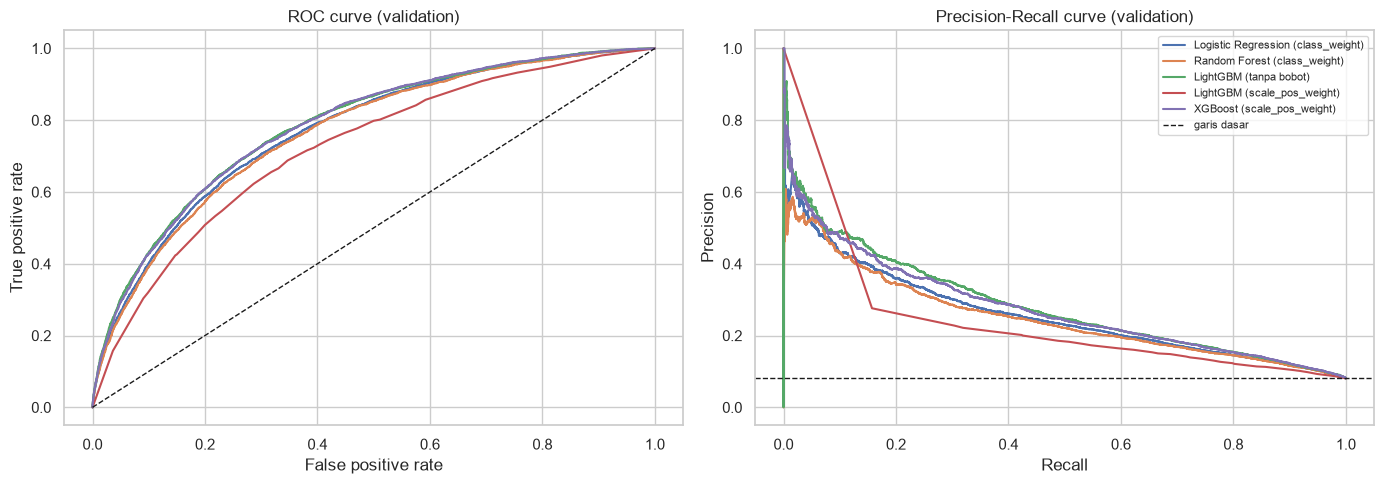

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for label, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_valid, proba)
    axes[0].plot(fpr, tpr, label=label)
    precision, recall, _ = precision_recall_curve(y_valid, proba)
    axes[1].plot(recall, precision, label=label)

axes[0].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[0].set(title="ROC curve (validation)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].axhline(y_valid.mean(), color="k", linestyle="--", linewidth=1, label="garis dasar")
axes[1].set(title="Precision-Recall curve (validation)", xlabel="Recall", ylabel="Precision")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7. Fitur terpenting (LightGBM, gain)
Ini ukuran global seberapa besar tiap fitur mengurangi error saat dipakai. Penjelasan yang lebih tepat dan per nasabah akan memakai SHAP di notebook berikutnya.

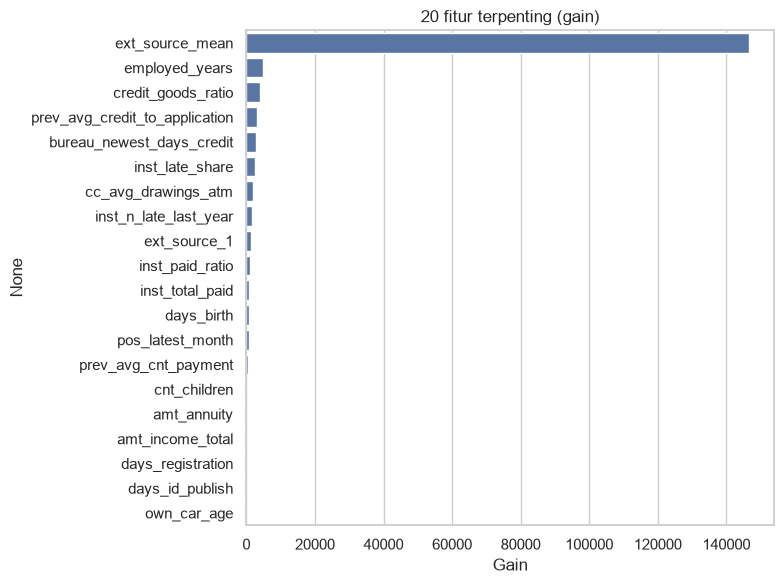

In [10]:
importance = (pd.Series(lgb_weighted.booster_.feature_importance(importance_type="gain"),
                        index=lgb_weighted.booster_.feature_name())
              .sort_values(ascending=False))
top = importance.head(20)
plt.figure(figsize=(8, 6))
sns.barplot(x=top.values, y=top.index, color="#4c72b0")
plt.title("20 fitur terpenting (gain)")
plt.xlabel("Gain")
plt.tight_layout()
plt.show()

## Catatan temuan (isi sendiri)
- Model dengan PR-AUC dan ROC-AUC tertinggi:
- Pengaruh penanganan imbalance (LightGBM tanpa bobot vs dengan `scale_pos_weight`):
- Perbandingan boosting vs model sederhana (logistic regression, Random Forest):
- Fitur teratas dan apakah fitur agregat dari tabel lain (bureau, installments, dst.) ikut masuk: